(hto_demultiplexing)=

# HTO demultiplexing

Cell hashing labels cells from each sample with a distinct oligonucleotide tag before the
samples are pooled. Depending on the protocol, tags are attached through antibodies or lipids.
Demultiplexing uses hashtag oligo (HTO) counts to recover sample assignments: a singlet has one
positive tag, a negative has none, and a doublet has more than one.

Pooling lets samples share a capture, but an incorrect assignment can mix their biological
signals. Inspect the assignments before comparing samples. This is separate from integrating
RNA and protein measurements in [](cite_seq.ipynb).

## Download the Cell Hashing example

We use the eight-donor PBMC experiment from @Stoeckius_2018, available as
[GSE108313](https://www.ncbi.nlm.nih.gov/geo/query/acc.cgi?acc=GSE108313). Each donor has one of
eight tags, BatchA through BatchH. The experiment also includes untagged HEK293T and mouse
NIH3T3 cells. We retain those controls here, so some negative assignments are expected.

The two downloads total about 34 MB. The HTO file supplies the tag counts; the RNA file lets
us select barcodes with RNA evidence before demultiplexing. We import only the small HTO
matrix into CyteArc. An HTO assay can also share a datastore with RNA, ADT, or ATAC assays
when their cell barcodes are aligned.

The example uses a temporary directory. Use a project directory instead if you want to keep
the downloaded files and Zarr store after closing the notebook.

In [1]:
# Download and verify the published count files.
import gzip
import hashlib
import shutil
from pathlib import Path
from tempfile import TemporaryDirectory
from urllib.request import urlopen

# Read count tables and write a sparse matrix to CyteArc.
import numpy as np
import pandas as pd
from scipy.sparse import csr_matrix
import cytearc

# Display the diagnostic figures.
import matplotlib.pyplot as plt

# Keep routine logs and progress bars out of the results.
cytearc.configure_output(level="WARNING", progress=False)

# Keep this example's downloads and store together.
work = TemporaryDirectory()
output_dir = Path(work.name)

Started: 2026-10-11T21:10:26.836097Z | Wall time: 0.557 s

In [2]:
# Pin the two public GEO files so a changed download cannot alter the example silently.
sources = {
    "hto": (
        "https://ftp.ncbi.nlm.nih.gov/geo/samples/GSM2895nnn/GSM2895283/suppl/"
        "GSM2895283_Hashtag-HTO-count.csv.gz",
        "68ab6cd853964026a79f5c3da58a901808eab18c25684b3eecd41ebb71b9bce2",
    ),
    "rna": (
        "https://ftp.ncbi.nlm.nih.gov/geo/samples/GSM2895nnn/GSM2895282/suppl/"
        "GSM2895282_Hashtag-RNA.umi.txt.gz",
        "98a2be289ce79c2a2104eeaff3e39528ea25dfa0b3f3c1faf7246843f65ce3d9",
    ),
}
paths = {}
for assay, (url, expected_digest) in sources.items():
    path = output_dir / url.rsplit("/", 1)[1]

    # Copy the response in blocks without holding the file in memory.
    with urlopen(url, timeout=60) as response, path.open("wb") as destination:
        shutil.copyfileobj(response, destination)

    # Reject a file whose contents differ from the verified source.
    with path.open("rb") as source:
        actual_digest = hashlib.file_digest(source, "sha256").hexdigest()
    if actual_digest != expected_digest:
        raise ValueError(f"Checksum mismatch for {path.name}")
    paths[assay] = path

# Show the size of each completed download.
pd.Series(
    {assay: path.stat().st_size / 1_000_000 for assay, path in paths.items()},
    name="Downloaded MB",
).round(2)

hto     1.07
rna    32.73
Name: Downloaded MB, dtype: float64

Started: 2026-10-11T21:10:27.395176Z | Wall time: 9.040 s

## Read the eight hashtag channels

The HTO CSV has tags along rows and barcodes along columns. Three rows, `bad_struct`,
`no_match`, and `total_reads`, describe read processing rather than hashtags. Remove those
before importing. For readable plots, shorten each tag identifier to its BatchA through
BatchH prefix; the suffix is its oligonucleotide sequence.

In [3]:
# Read the small tag table and remove the three sequencing-summary rows.
hto_counts = pd.read_csv(paths["hto"], index_col=0).drop(
    index=["bad_struct", "no_match", "total_reads"]
).T

# Use barcodes as rows and short tag identifiers as columns.
hto_counts.index.name = "barcode"
hto_counts.columns = hto_counts.columns.str.split("-").str[0]
hto_counts.head()

,BatchA,BatchB,BatchC,BatchD,BatchE,BatchF,BatchG,BatchH
barcode,,,,,,,,
GGCGACTAGAGGACGG,30,16,26,2698,8,15,55,32
CATCAAGGTCTTGTCC,4,39,0,22,24,47,21,17
AAACCTGAGTGATCGG,12,15,19,2,32,12,76,3
TGAGGGAGTACTTAGC,26,20,13,24,6,75,76,32
CCTAAAGAGATGTGGC,7,4,12,24,1755,19,82,5


Started: 2026-10-11T21:10:36.436754Z | Wall time: 1.864 s

## Choose barcodes using RNA counts

HTO signal alone does not establish that a droplet contains a cell. We keep barcodes present
in both files with at least 200 RNA UMIs, following the study's initial RNA threshold.
This is a teaching selection, not a reproduction of every filtering step in the paper.
In particular, we do not remove the untagged control cell lines.

The RNA table has 40,899 genes and 50,000 barcodes and expands to about 4 GB. We only need
one total per barcode, so read and sum one gene at a time. This step can take about a minute.

In [4]:
# Sum RNA UMIs by barcode without loading the complete expression matrix.
with gzip.open(paths["rna"], "rt") as source:
    rna_barcodes = next(source).rstrip().split("\t")[1:]
    rna_totals = np.zeros(len(rna_barcodes), dtype=np.int64)
    for line in source:
        gene, values = line.split("\t", 1)
        gene_counts = np.fromstring(values, sep="\t", dtype=np.int64)
        if gene_counts.size != rna_totals.size:
            raise ValueError(f"Unexpected number of RNA counts for {gene}")
        rna_totals += gene_counts

# Require RNA support and a matching HTO barcode.
rna_totals = pd.Series(rna_totals, index=rna_barcodes, name="RNA_nCounts")
shared_barcodes = rna_totals.index.intersection(hto_counts.index)
selected_barcodes = shared_barcodes[rna_totals.loc[shared_barcodes] >= 200]
selected_counts = hto_counts.loc[selected_barcodes]

# Report the input population before assigning any tags.
pd.Series({
    "Barcodes in the HTO file": len(hto_counts),
    "Barcodes in both files": len(shared_barcodes),
    "Shared barcodes with at least 200 RNA UMIs": len(selected_counts),
}, name="Barcodes")

Barcodes in the HTO file                      65000
Barcodes in both files                        39842
Shared barcodes with at least 200 RNA UMIs    21522
Name: Barcodes, dtype: int64

Started: 2026-10-11T21:10:38.302154Z | Wall time: 32.811 s

## Import the HTO assay

Declare the assay as type `HTO`. The store contains eight features, so
`min_features_per_cell=-1` keeps the selected barcodes without applying the usual first-open
feature-count floor. RNA totals are retained as cell metadata; the RNA matrix is not copied.

This cell creates a new store. Rerun the notebook from the beginning to use a fresh temporary
directory, or choose another output path when repeating the import.

In [5]:
# Write the selected raw tag counts into a new HTO store.
store_path = output_dir / "cell_hashing.zarr"
cytearc.SparseToZarr(
    csr_matrix(selected_counts.to_numpy()),
    str(store_path),
    cell_ids=selected_counts.index.to_numpy(),
    feature_ids=selected_counts.columns.to_numpy(),
    assay_name="HTO",
    assay_type="HTO",
    nthreads=4,
    mem_budget="1G",
).dump()

# Preserve every RNA-supported barcode when opening the small tag panel.
ds = cytearc.DataStore(
    str(store_path),
    default_assay="HTO",
    min_features_per_cell=-1,
    nthreads=4,
    mem_budget="1G",
)

# Align the imported RNA totals to the datastore's barcodes.
ds.cells.insert("RNA_nCounts", rna_totals.loc[ds.cells.fetch_all("ids")].to_numpy())
ds

DataStore has 21522 (21522) cells with 1 assays: HTO
   Cell metadata:
            'I', 'ids', 'names', 'HTO_nCounts', 'HTO_nFeatures', 
            'RNA_nCounts'
   HTO assay has 8 features and following metadata:
            'I', 'ids', 'names', 'dropOuts', 'nCells'

Started: 2026-10-11T21:11:11.114597Z | Wall time: 1.481 s

## Assign singlets, doublets, and negatives

CyteArc follows the general HTOdemux strategy. It normalizes each tag with CLR, uses K-means
to form one more cluster than the number of tags, and chooses each tag's lowest-count cluster
as its background. Counts above the fitted negative-binomial distribution's 99th percentile
are positive. This differs from Seurat's default clustering, so the assignments need not
match Seurat's results.

`qc.hto_demultiplexing` saves an immutable identity artifact and leaves cell metadata
unchanged. A singlet receives its strongest normalized tag's identifier. `Negative` means
no positive tags, and `Doublet` means at least two; the latter can also include higher-order
multiplets.

In [6]:
# Freeze the selected barcodes and demultiplex their raw HTO counts.
cell_selection = ds.snapshot_cell_selection("I")
identities = ds.qc.hto_demultiplexing(cell_selection, random_seed=0)

# Load assignments with their barcode index rather than relying on row order.
labels = ds.artifacts.load_values(identities).to_pandas()
labels.name = "HTO identity"

# Summarize the three classes while retaining each singlet's tag in labels.
classes = labels.where(labels.isin(["Negative", "Doublet"]), "Singlet")
class_counts = classes.value_counts().reindex(["Singlet", "Doublet", "Negative"])
pd.DataFrame({
    "Barcodes": class_counts,
    "Percent": (100 * class_counts / len(labels)).round(1),
})

,Barcodes,Percent
HTO identity,,
Singlet,16322,75.8
Doublet,3203,14.9
Negative,1997,9.3


Started: 2026-10-11T21:11:12.597312Z | Wall time: 0.853 s

This run assigns 16,322 singlets, 3,203 doublets, and 1,997 negatives. These are classifications
for the selection above, not independently validated identities or an estimate of the loading
rate. Negative calls can include the untagged controls as well as cells with weak tag signal.
A negative label alone does not tell us which explanation applies to a particular barcode.

In [7]:
# Count assignments for each tag and retain the two unresolved classes.
tag_names = ds.HTO.feats.fetch_all("ids").astype(str).tolist()
identity_order = tag_names + ["Doublet", "Negative"]
labels.value_counts().reindex(identity_order).rename("Barcodes").to_frame()

,Barcodes
HTO identity,
BatchA,2193
BatchB,2281
BatchC,2141
BatchD,1943
BatchE,1764
BatchF,1791
BatchG,2007
BatchH,2202
Doublet,3203


Started: 2026-10-11T21:11:13.451191Z | Wall time: 0.010 s

## Inspect the tag signal

The heatmap shows mean CLR-normalized HTO counts for each assigned group. Singlets should
be enriched for their assigned tag. Doublets combine different tag pairs, so their group
average can show several tags even though an individual doublet need not carry all eight.
The plot summarizes the same measurements used for assignment; it is a diagnostic, not an
independent validation.

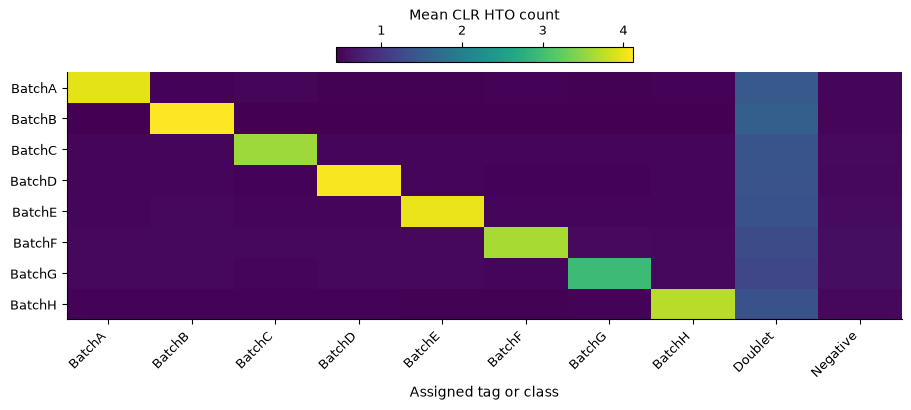

Started: 2026-10-11T21:11:13.461739Z | Wall time: 0.219 s

In [8]:
# Compare all eight tag signals across the saved assignment groups.
heatmap = ds.plots.matrixplot(
    features=tag_names,
    groups=identities,
    group_order=identity_order,
    figsize=(9, 4),
    show=False,
)

# Label the color scale and groups for the HTO assay.
heatmap.axes["matrixplot"].images[0].colorbar.set_label("Mean CLR HTO count")
heatmap.axes["matrixplot"].set_xlabel("Assigned tag or class")
plt.show()

Group averages can hide ambiguous cells. Compare the full BatchA and BatchB distributions
below. An assigned singlet group can still contain low background counts for other tags;
a nonzero count is not automatically a positive tag call.

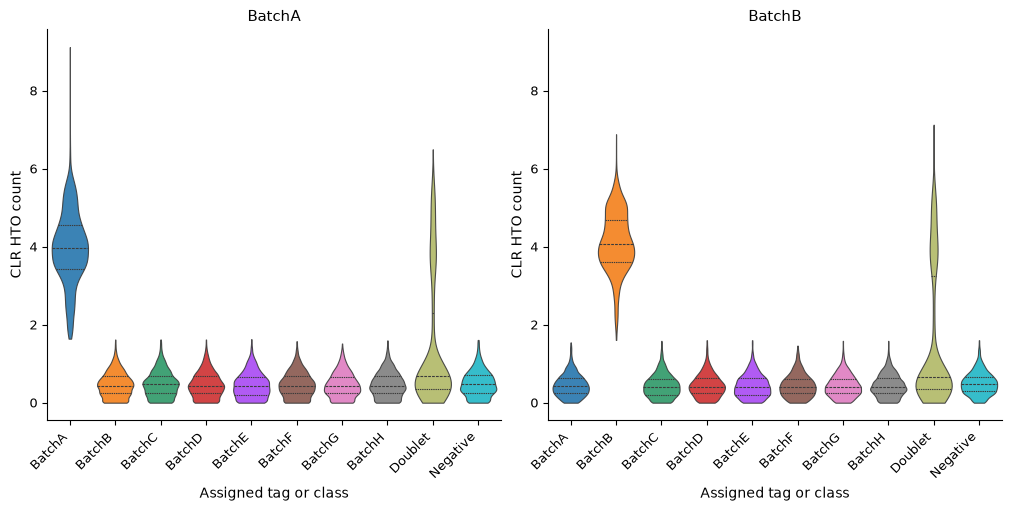

Started: 2026-10-11T21:11:13.682039Z | Wall time: 0.521 s

In [9]:
# Inspect individual-cell distributions for two tags using the same saved identities.
distributions = ds.plots.distribution(
    ["BatchA", "BatchB"],
    grouping=identities,
    groups=identity_order,
    max_points=0,
    italicize_features=False,
    figsize=(10, 5),
    show=False,
)

# Name the plotted measurements and assignment groups.
for ax in distributions.axes.values():
    ax.set_xlabel("Assigned tag or class")
    ax.set_ylabel("CLR HTO count")
plt.show()

## Keep an explicit singlet selection

Select the eight tag identifiers to retain singlets. The resulting artifact records the
selection without deleting negative or doublet rows. In a datastore with matching RNA or
other assays, pass it as `cell_selection=` to downstream analyses.

In [10]:
# Keep barcodes assigned to one of the eight tags.
singlets = ds.select_cells(identities, include=tag_names)
singlet_mask = np.asarray(ds.artifacts.load(singlets)["values"][:], dtype=bool)

# Confirm how many barcodes the selection retains and how many remain in the store.
pd.Series({
    "Selected singlets": int(singlet_mask.sum()),
    "Barcodes retained in the store": ds.cells.N,
}, name="Barcodes")

Selected singlets                 16322
Barcodes retained in the store    21522
Name: Barcodes, dtype: int64

Started: 2026-10-11T21:11:14.205044Z | Wall time: 0.040 s

## Common mistakes and limitations

- Feeding sequencing-summary rows or normalized values into demultiplexing changes the
  input. Use only the raw hashtag channels and check that barcodes match across assays.
- Treating the labels as ground truth: background and weak staining affect assignments.
  Inspect tag distributions, and do not relabel negatives or doublets as a donor without
  further evidence.
- Assuming HTO singlets cannot be multiplets: two cells with the same tag can escape
  detection. HTO demultiplexing does not replace RNA quality control or RNA doublet scoring;
  see [](quality_control.ipynb).

The [DataStore API reference](/api/datastore.html) documents the current demultiplexing signature.